# 06 · Leaky integrate-and-fire (LIF): integration, threshold, and reset
## Goal
Add an analytically tractable hybrid single-neuron baseline to the project's continuous-flow models. Study passive integration, firing onset, pulse responses, temporal summation, refractory rules, and numerical event accuracy.

**Scope:** one deterministic neuron; no noise, adaptation, synaptic dynamics, biological spike waveform, or network simulation. The spike threshold, reset, and refractory hold are imposed rules. These are not a smooth recovery mechanism or a SNIC normal form.

Everything is self-contained. Figures, tables, spike times, and a JSON summary are saved under `results/lif/` relative to the execution directory. No external data or internet connection are required.

## Setup
### Dimensionless convention and optional physical mapping
Start from $\tau_m\dot V=-(V-E_L)+RI(t)$. Define
$$t=t_{physical}/\tau_m,\quad v=(V-E_L)/(V_{th}-E_L),\quad j=RI/(V_{th}-E_L).$$
Then
$$\dot v=-v+j(t),\qquad v_{cut}=1,\qquad v_r=0.$$
At a positive threshold crossing emit a spike, reset immediately to $v_r$, and hold there for $\rho=0.1$ time units. Input during the hold is ignored. Time then resumes under the input currently present, even if input changed during the hold. $\rho=0$ is also examined.

Time, voltage, and drive are dimensionless. Frequencies are inverse model time, **not Hz**. A physical frequency would be $f/\tau_m$ with $\tau_m$ expressed in seconds; no measured timescale or cell parameters are assigned here. These definitions implement the standard [LIF construction](https://neuronaldynamics.epfl.ch/online/Ch1.S3.html).

### Methods and measurement
- DOP853 integrates each active segment; terminal event interpolation locates spikes. Input jumps and reset/hold intervals are handled separately.
- The refractory clock persists across protocol boundaries. Dotted vertical plot segments indicate artificial reset jumps, not action-potential shapes.
- At constant $j\leq1$, a state below threshold cannot reach it in finite time. The implementation disables the crossing event on such segments, avoiding a false spike when a critical asymptote rounds to 1.
- Exact flow and spike-time formulas are the references. RK45 tolerance sweeps test event accuracy. Numerical discrepancies are not confidence intervals.
- At the event itself the sampled state is defined right-continuously as the reset value.

Use a Python kernel with NumPy, SciPy, pandas, Matplotlib, IPython, and Jupyter. Nothing is installed by this notebook.

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import scipy
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

plt.rcParams.update({'figure.figsize': (9.3, 4.2), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.18,
                     'figure.dpi': 110, 'savefig.dpi': 160})
pd.set_option('display.precision', 7)
COLORS = {'flow': '#2166AC', 'comparison': '#C56A18', 'neutral': '#444444'}
VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__,
            'scipy': scipy.__version__, 'pandas': pd.__version__,
            'matplotlib': matplotlib.__version__}
print(VERSIONS)
EVENT_LOG = []

def show_and_save(fig, stem):
    fig.savefig(OUTPUT_DIR/f'{stem}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

def log_run(label, run):
    for index, time in enumerate(run['spikes']):
        EVENT_LOG.append({'experiment': label, 'spike_index': index+1, 'time': time})

OUTPUT_DIR = Path('results')/'lif'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESET, CUT, REFRACTORY = 0., 1., 0.1

def rhs(v, drive, cutoff):
    return -v+drive

def event_allowed(drive, cutoff):
    return drive > cutoff

def exact_flow(times, v0, drive):
    return drive+(v0-drive)*np.exp(-np.asarray(times))

def flight_time(drive, initial=RESET, cutoff=CUT):
    if drive <= cutoff:
        return np.inf
    return float(np.log((drive-initial)/(drive-cutoff)))

def exact_period(drive, refractory=REFRACTORY):
    return flight_time(drive)+refractory

{'python': '3.12.2', 'numpy': '2.2.6', 'scipy': '1.18.1', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}


## Steps
### 1. Linear flow versus the hybrid firing rule
Without threshold/reset, the equilibrium is $v_*=j$, with eigenvalue $-1$ for **every** constant drive. With the hybrid threshold, equilibria above $v=1$ are outside the active state domain. Repetitive firing begins when $j>1$; the linear equilibrium does not lose stability.

For $j\leq1$ and initial $v_0<1$,
$$v(t)=j+(v_0-j)e^{-t}$$
never reaches threshold in finite time. At $j=1$ it approaches the threshold asymptotically. This onset mechanism differs from the theta/QIF SNIC, even though both have frequency tending to zero at onset.

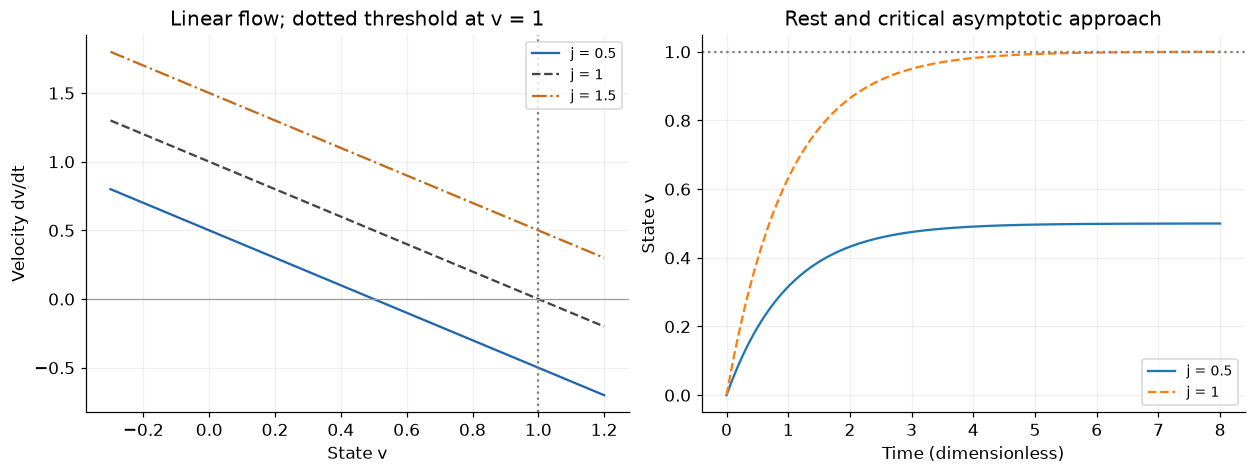

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11.3, 4.2), layout='constrained')
vv = np.linspace(-0.3, 1.2, 400)
for drive, style, color in [(0.5, '-', COLORS['flow']), (1., '--', COLORS['neutral']),
                              (1.5, '-.', COLORS['comparison'])]:
    axes[0].plot(vv, -vv+drive, style, color=color, label=f'j = {drive:g}')
axes[0].axvline(1, color='0.5', linestyle=':')
axes[0].axhline(0, color='0.6', linewidth=0.8)
axes[0].set(xlabel='State v', ylabel='Velocity dv/dt', title='Linear flow; dotted threshold at v = 1')
axes[0].legend(fontsize=9, loc='upper right')
for drive, style in [(0.5, '-'), (1., '--')]:
    tt = np.linspace(0, 8, 501)
    axes[1].plot(tt, exact_flow(tt, 0, drive), style, label=f'j = {drive:g}')
axes[1].axhline(1, color='0.5', linestyle=':')
axes[1].set(xlabel='Time (dimensionless)', ylabel='State v', title='Rest and critical asymptotic approach')
axes[1].legend(fontsize=9, loc='lower right')
show_and_save(fig, '01_linear_flow_and_onset')

### 2. Reusable event/reset integrator
The following implementation is deliberately explicit about active flow, reset, and refractory hold. It permits piecewise-constant inputs and a hold that straddles an input jump. Unlike a fixed time-step threshold test, it does not round spike times to a plotting grid.

In [5]:
def simulate(protocol, initial, *, reset=RESET, cutoff=CUT, refractory=REFRACTORY,
             rtol=1e-9, atol=1e-11, method='DOP853', max_step=0.25):
    """Piecewise-constant drives; interpolated events; refractory clock spans segments."""
    if not reset < cutoff or not initial < cutoff or refractory < 0:
        raise ValueError('Require reset and initial below cutoff; refractory >= 0.')
    if not len(protocol) or protocol[0][0] != 0:
        raise ValueError('Protocol must start at t=0.')
    blocks, spikes = [], []
    state, ready_time, previous_stop = float(initial), -np.inf, 0.
    def event(t, y):
        return y[0]-cutoff
    event.direction = 1
    event.terminal = True
    for start, stop, drive in protocol:
        if not np.isclose(start, previous_stop) or not stop > start:
            raise ValueError('Require positive-duration contiguous segments.')
        now = float(start)
        while now < stop-1e-12:
            if now < ready_time:
                hold_end = min(stop, ready_time)
                blocks.append({'kind': 'hold', 'start': now, 'stop': hold_end,
                               'value': reset, 'drive': drive})
                state, now = float(reset), float(hold_end)
                if now >= stop-1e-12:
                    break
            sol = solve_ivp(lambda t, y: [rhs(y[0], drive, cutoff)],
                            (now, stop), [state], method=method,
                            rtol=rtol, atol=atol, max_step=max_step,
                            dense_output=True,
                            events=event if event_allowed(drive, cutoff) else None)
            if not sol.success:
                raise RuntimeError(sol.message)
            blocks.append({'kind': 'flow', 'start': now, 'stop': float(sol.t[-1]),
                           'solution': sol, 'drive': drive})
            if sol.status != 1:
                state, now = float(sol.y[0, -1]), float(stop)
            else:
                time = float(sol.t_events[0][0])
                if time <= now+1e-13:
                    raise RuntimeError('No positive flight time after reset.')
                spikes.append(time)
                state, now, ready_time = float(reset), time, time+refractory
                if len(spikes) > 10000:
                    raise RuntimeError('Spike safety limit exceeded.')
        previous_stop = float(stop)
    return {'blocks': blocks, 'spikes': np.array(spikes), 'final_state': state,
            'reset': reset, 'cutoff': cutoff, 'refractory': refractory,
            'stop': previous_stop}

def sample_run(run, times):
    times = np.asarray(times, dtype=float)
    values = np.full(times.shape, np.nan)
    for block in run['blocks']:
        mask = (times >= block['start']) & (times <= block['stop'])
        if not np.any(mask):
            continue
        values[mask] = block['value'] if block['kind'] == 'hold' else block['solution'].sol(times[mask])[0]
    # Post-reset value defines the right-continuous state at event times.
    for time in run['spikes']:
        values[np.abs(times-time) < 1e-11] = run['reset']
    if not np.isfinite(values).all():
        raise ValueError('Sample times outside simulated coverage.')
    return values

def plot_state(ax, run, *, color, label=None, linestyle='-'):
    """Draw flow/holds separately: no artificial action-potential waveform."""
    labeled = False
    for block in run['blocks']:
        tt = np.linspace(block['start'], block['stop'], 150)
        vv = np.full_like(tt, block['value']) if block['kind'] == 'hold' else block['solution'].sol(tt)[0]
        ax.plot(tt, vv, linestyle, color=color, linewidth=1.2,
                label=label if not labeled else None)
        labeled = True
    for time in run['spikes']:
        ax.plot([time, time], [run['reset'], run['cutoff']], ':', color=color,
                alpha=0.45, linewidth=0.8)

def measured_period(run):
    if len(run['spikes']) < 4:
        raise ValueError('At least four events required for an ISI benchmark.')
    return float(np.diff(run['spikes']).mean())

### 3. Constant-drive traces and exact firing-rate curve
From reset, the active flight time for $j>1$ is
$$F(j)=\log\frac{j-v_r}{j-1},\qquad T(j)=F(j)+\rho,\qquad f(j)=1/T(j).$$
The first spike from reset occurs at $F$, not $T$, because no initial refractory hold is applied. Subsequent spikes occur at $F+nT$. For $j\leq1$, asymptotic frequency is zero.

As $j\downarrow1$, the period diverges logarithmically. With $\rho>0$, the rate tends to $1/\rho$ for very large input; this ceiling is imposed by the hold. The zero-hold model has no such finite ceiling. Numerical rates below are estimated from ISIs, not finite-window counts.

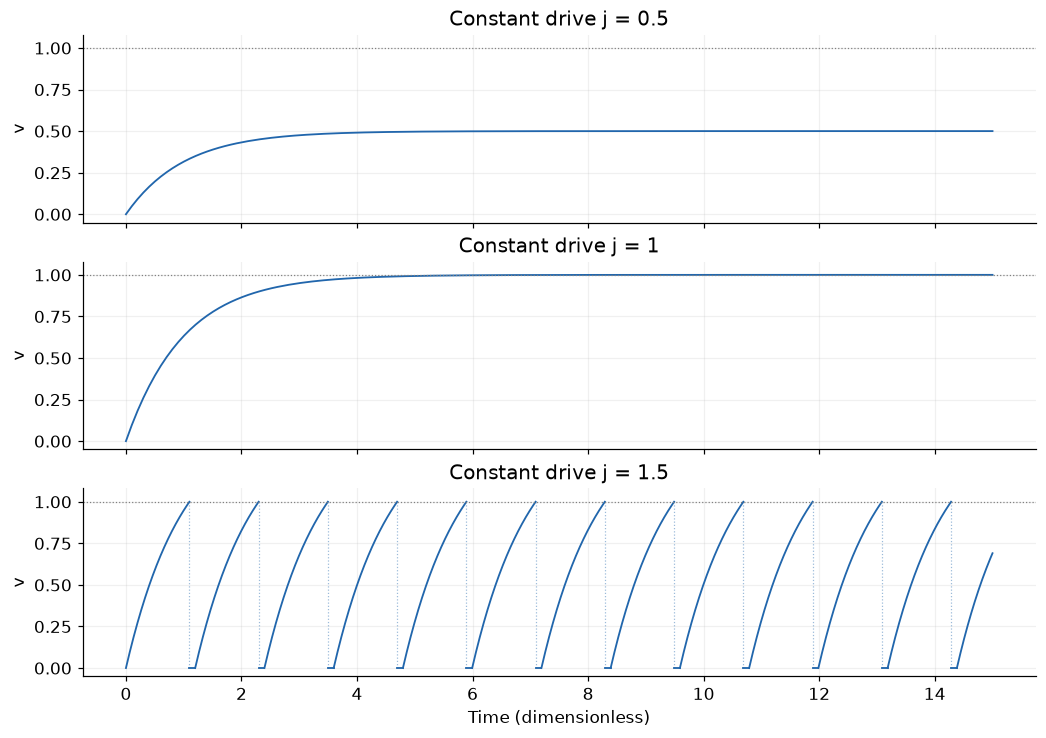

,j,period_exact,period_numeric,frequency_exact,frequency_numeric,relative_period_error
0,1.0001000,9.3104404,9.3104404,0.1074063,0.1074063,1.7876811e-12
6,1.0044814,5.5122901,5.5122901,0.1814128,0.1814128,9.7610808e-13
12,1.2008299,1.8883100,1.8883100,0.5295741,0.5295741,3.8674619e-12
18,10.0000000,0.2053605,0.2053605,4.8694852,4.8694852,2.1760371e-14


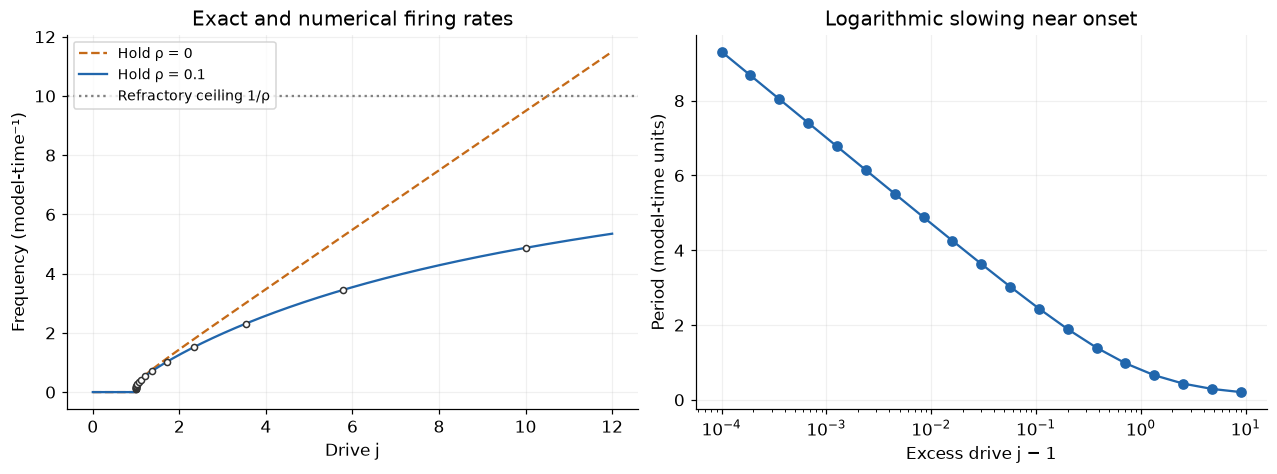

In [7]:
trace_runs = {}
fig, axes = plt.subplots(3, 1, figsize=(9.4, 6.6), sharex=True, layout='constrained')
for ax, drive in zip(axes, [0.5, 1., 1.5]):
    run = simulate([(0, 15, drive)], RESET)
    trace_runs[drive] = run
    log_run(f'constant_j_{drive:g}', run)
    plot_state(ax, run, color=COLORS['flow'])
    ax.axhline(CUT, color='0.5', linestyle=':', linewidth=0.8)
    ax.set(title=f'Constant drive j = {drive:g}', ylabel='v', ylim=(-0.05, 1.08))
axes[-1].set_xlabel('Time (dimensionless)')
show_and_save(fig, '02_constant_drive_traces')

rate_rows = []
for drive in 1+np.geomspace(1e-4, 9., 19):
    F, T = flight_time(drive), exact_period(drive)
    run = simulate([(0, F+3.5*T, float(drive))], RESET)
    observed_T = measured_period(run)
    rate_rows.append({'j': drive, 'period_exact': T, 'period_numeric': observed_T,
                      'frequency_exact': 1/T, 'frequency_numeric': 1/observed_T,
                      'relative_period_error': abs(observed_T/T-1)})
rate_table = pd.DataFrame(rate_rows)
rate_table.to_csv(OUTPUT_DIR/'firing_rate_curve.csv', index=False)
display(rate_table.iloc[[0, 6, 12, 18]])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), layout='constrained')
j_grid = np.linspace(0, 12, 1001)
for rho, style, color in [(0., '--', COLORS['comparison']), (REFRACTORY, '-', COLORS['flow'])]:
    rates = [0. if j <= 1 else 1/exact_period(j, rho) for j in j_grid]
    axes[0].plot(j_grid, rates, style, color=color, label=f'Hold ρ = {rho:g}')
axes[0].plot(rate_table.j, rate_table.frequency_numeric, 'o', mfc='white', mec='0.2', markersize=4)
axes[0].axhline(1/REFRACTORY, color='0.5', linestyle=':', label='Refractory ceiling 1/ρ')
axes[0].set(xlabel='Drive j', ylabel='Frequency (model-time⁻¹)', title='Exact and numerical firing rates')
axes[0].legend(fontsize=9, loc='upper left')
axes[1].semilogx(rate_table.j-1, rate_table.period_numeric, 'o-', color=COLORS['flow'])
axes[1].set(xlabel='Excess drive j − 1', ylabel='Period (model-time units)', title='Logarithmic slowing near onset')
show_and_save(fig, '03_firing_rate_curve')

### 4. Pulse strength–duration relation
From exact rest $v_0=0$ at baseline $j=0$, a constant pulse $A>1$ first reaches threshold after
$$D_{crit}(A)=-\log(1-1/A).$$
Equivalently $A_{crit}(D)=1/(1-e^{-D})$. Equality is threshold contact at the pulse endpoint under the declared event convention. There is no finite critical duration for $A\leq1$ from rest.

Use amplitude $A=1.5$, onset $t=2$, and durations $0.8D_{crit}$ and $1.2D_{crit}$. A below-threshold state decays after the pulse; this LIF model cannot produce a delayed post-pulse spike at zero baseline. The stronger example fires during the pulse.

,duration_over_critical,duration,n_spikes,first_spike_time,pulse_off_time,final_v
0,0.8,0.8788898,0,NaN,2.8788898,3.2170850e-08
1,1.2,1.3183347,1,3.0986123,3.3183347,9.6332683e-09


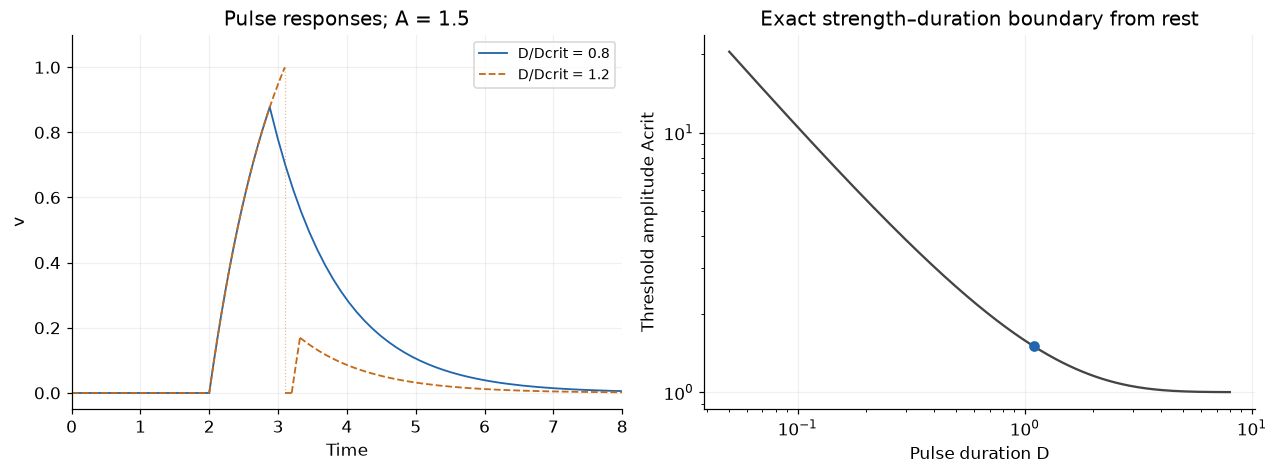

In [9]:
PULSE_A, PULSE_ON = 1.5, 2.
D_CRIT = flight_time(PULSE_A, initial=0.)
pulse_runs, pulse_rows = {}, []
for factor in [0.8, 1.2]:
    duration = factor*D_CRIT
    off = PULSE_ON+duration
    run = simulate([(0, PULSE_ON, 0), (PULSE_ON, off, PULSE_A), (off, 20, 0)], 0.)
    pulse_runs[factor] = run
    log_run(f'pulse_D_over_Dcrit_{factor:g}', run)
    pulse_rows.append({'duration_over_critical': factor, 'duration': duration,
                       'n_spikes': len(run['spikes']),
                       'first_spike_time': float(run['spikes'][0]) if len(run['spikes']) else np.nan,
                       'pulse_off_time': off, 'final_v': run['final_state']})
pulse_table = pd.DataFrame(pulse_rows)
pulse_table.to_csv(OUTPUT_DIR/'pulse_responses.csv', index=False)
display(pulse_table)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), layout='constrained')
for factor, style, color in [(0.8, '-', COLORS['flow']), (1.2, '--', COLORS['comparison'])]:
    plot_state(axes[0], pulse_runs[factor], color=color, linestyle=style, label=f'D/Dcrit = {factor:g}')
axes[0].set(xlabel='Time', ylabel='v', title='Pulse responses; A = 1.5', xlim=(0, 8), ylim=(-0.05, 1.1))
axes[0].legend(fontsize=9, loc='upper right')
durations = np.geomspace(0.05, 8, 300)
axes[1].loglog(durations, 1/(-np.expm1(-durations)), color=COLORS['neutral'])
axes[1].plot(D_CRIT, PULSE_A, 'o', color=COLORS['flow'])
axes[1].set(xlabel='Pulse duration D', ylabel='Threshold amplitude Acrit', title='Exact strength–duration boundary from rest')
show_and_save(fig, '04_pulse_thresholds')

### 5. Temporal summation of individually subthreshold pulses
Each amplitude-2.5, duration-0.3 pulse alone reaches $2.5(1-e^{-0.3})<1$. Two identical pulses with onset gap 0.35 can sum sufficiently to fire; an onset gap of 2 lets more charge leak away. The total delivered input is the same in the two protocols. This is leaky temporal integration, not intrinsic adaptation.

The dotted vertical jumps in the close-pulse trace are reset markers. The far-pulse protocol has no spike.

,onset_gap,total_input_integral,n_spikes
0,0.35,1.5,1
1,2.00,1.5,0


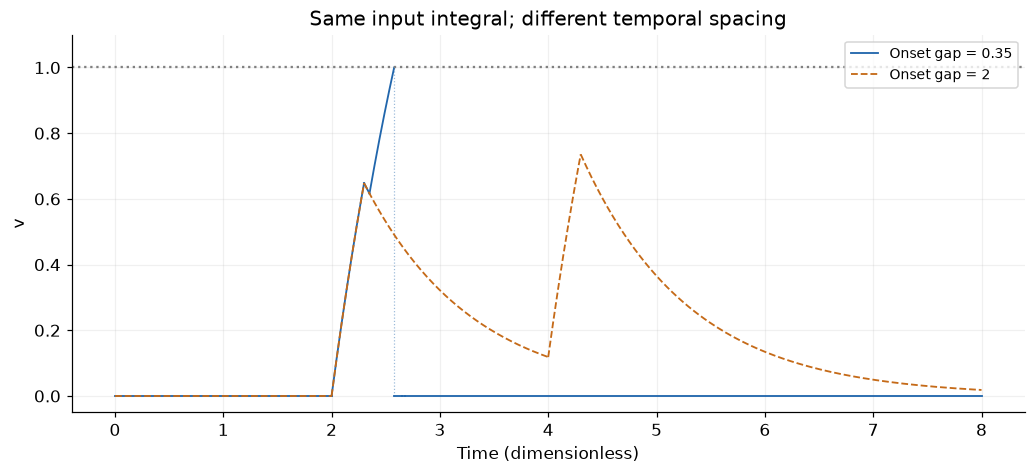

In [11]:
summation_runs, summation_rows = {}, []
for gap in [0.35, 2.]:
    second = 2+gap
    protocol = [(0, 2, 0), (2, 2.3, 2.5), (2.3, second, 0),
                 (second, second+0.3, 2.5), (second+0.3, 8, 0)]
    run = simulate(protocol, 0.)
    summation_runs[gap] = run
    log_run(f'temporal_summation_gap_{gap:g}', run)
    summation_rows.append({'onset_gap': gap, 'total_input_integral': 1.5,
                           'n_spikes': len(run['spikes'])})
summation_table = pd.DataFrame(summation_rows)
summation_table.to_csv(OUTPUT_DIR/'temporal_summation.csv', index=False)
display(summation_table)
fig, ax = plt.subplots(figsize=(9.3, 4.2), layout='constrained')
for gap, color, style in [(0.35, COLORS['flow'], '-'), (2., COLORS['comparison'], '--')]:
    plot_state(ax, summation_runs[gap], color=color, linestyle=style, label=f'Onset gap = {gap:g}')
ax.axhline(1, color='0.5', linestyle=':')
ax.set(xlabel='Time (dimensionless)', ylabel='v', title='Same input integral; different temporal spacing', ylim=(-0.05, 1.1))
ax.legend(fontsize=9, loc='upper right')
show_and_save(fig, '05_temporal_summation')

### 6. Numerical convergence and refractory-boundary test
At $j=1.5$, compare numerical periods and event times with the exact formulas while tightening RK45 tolerances. Separately test subthreshold flow against its exponential solution.

For a hold spanning an input change: begin at $j=3$, change to $j=10$ halfway through the first refractory hold, and verify the next spike occurs at $t_1+\rho+F(10)$. Input does not prematurely end the hold. This checks behavior that a period-only constant-drive test would miss.

,rtol,relative_period_error,max_spike_time_error
0,1.0000000e-03,2.3498859e-04,1.4083011e-03
1,1.0000000e-05,1.9031427e-06,1.1405651e-05
2,1.0000000e-07,1.1254457e-08,6.7448644e-08
3,1.0000000e-09,8.5821572e-11,5.1433346e-10
4,1.0000000e-11,1.9123592e-12,1.1485035e-11


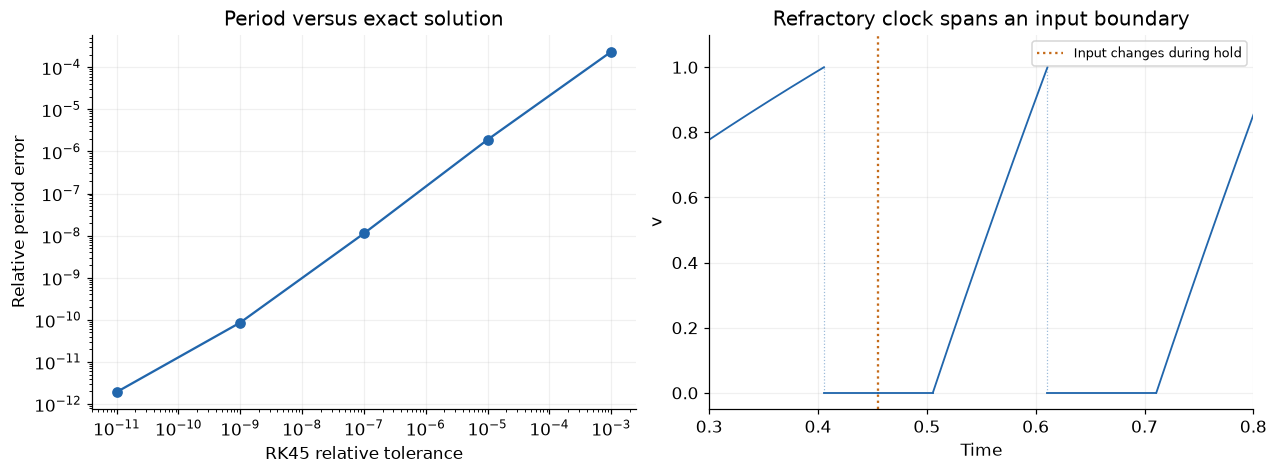

In [13]:
benchmark_j = 1.5
F_REF, T_REF = flight_time(benchmark_j), exact_period(benchmark_j)
convergence_rows = []
for tol in [1e-3, 1e-5, 1e-7, 1e-9, 1e-11]:
    run = simulate([(0, F_REF+4.5*T_REF, benchmark_j)], 0., method='RK45',
                    rtol=tol, atol=tol/100, max_step=1.)
    expected = F_REF+np.arange(len(run['spikes']))*T_REF
    convergence_rows.append({'rtol': tol, 'relative_period_error': abs(measured_period(run)/T_REF-1),
                             'max_spike_time_error': float(np.max(abs(run['spikes']-expected)))})
convergence_table = pd.DataFrame(convergence_rows)
convergence_table.to_csv(OUTPUT_DIR/'solver_convergence.csv', index=False)
display(convergence_table)
subthreshold = simulate([(0, 10, 0.6)], 0.2)
tt = np.linspace(0, 10, 1001)
flow_error = float(np.max(abs(sample_run(subthreshold, tt)-exact_flow(tt, 0.2, 0.6))))
first = flight_time(3.)
boundary = first+REFRACTORY/2
guard_run = simulate([(0, boundary, 3.), (boundary, 2., 10.)], 0.)
expected_second = first+REFRACTORY+flight_time(10.)
guard_error = abs(guard_run['spikes'][1]-expected_second)
hold_value = sample_run(guard_run, [first+0.075])[0]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), layout='constrained')
axes[0].loglog(convergence_table.rtol, convergence_table.relative_period_error, 'o-', color=COLORS['flow'])
axes[0].set(xlabel='RK45 relative tolerance', ylabel='Relative period error', title='Period versus exact solution')
plot_state(axes[1], guard_run, color=COLORS['flow'])
axes[1].axvline(boundary, color=COLORS['comparison'], linestyle=':', label='Input changes during hold')
axes[1].set(xlabel='Time', ylabel='v', title='Refractory clock spans an input boundary', xlim=(0.3, 0.8), ylim=(-0.05, 1.1))
axes[1].legend(fontsize=8.5, loc='upper right')
show_and_save(fig, '06_convergence_and_refractory_guard')

## Checks
Accuracy criteria are declared for these experiments. Exact formulas validate active flow and repeated events; protocol assertions validate pulse counts, temporal summation, and hold semantics. They do not establish a biological refractory time or extend the model's scope.

In [15]:
checks = [
    ('Subthreshold flow versus exact exponential', flow_error, 1e-8),
    ('Maximum rate-curve relative period error', rate_table.relative_period_error.max(), 1e-7),
    ('Tight RK45 relative period error', convergence_table.relative_period_error.iloc[-1], 1e-8),
    ('Tight RK45 maximum spike-time error', convergence_table.max_spike_time_error.iloc[-1], 1e-7),
    ('Hold across input-boundary: next spike error', guard_error, 1e-8),
    ('Held state remains exactly at reset', abs(hold_value-RESET), 1e-12)]
check_table = pd.DataFrame(checks, columns=['check', 'observed_error', 'limit'])
check_table['passed'] = check_table.observed_error < check_table.limit
assert check_table.passed.all(), check_table.loc[~check_table.passed]
assert len(trace_runs[0.5]['spikes']) == len(trace_runs[1.]['spikes']) == 0
assert pulse_table.n_spikes.tolist() == [0, 1]
assert pulse_table.first_spike_time.iloc[1] < pulse_table.pulse_off_time.iloc[1]
assert summation_table.n_spikes.tolist() == [1, 0]
assert convergence_table.relative_period_error.iloc[-1] < convergence_table.relative_period_error.iloc[0]
assert np.all(np.diff(guard_run['spikes']) >= REFRACTORY)
assert sample_run(guard_run, [guard_run['spikes'][0]])[0] == RESET
check_table.to_csv(OUTPUT_DIR/'validation_checks.csv', index=False)
pd.DataFrame(EVENT_LOG).to_csv(OUTPUT_DIR/'spike_events.csv', index=False)
display(check_table)
print('All accuracy criteria and hybrid/protocol assertions passed.')

,check,observed_error,limit,passed
0,Subthreshold flow versus exact exponential,6.6571193e-12,1.0000000e-08,True
1,Maximum rate-curve relative period error,4.0618509e-11,1.0000000e-07,True
2,Tight RK45 relative period error,1.9123592e-12,1.0000000e-08,True
3,Tight RK45 maximum spike-time error,1.1485035e-11,1.0000000e-07,True
4,Hold across input-boundary: next spike error,2.6623148e-13,1.0000000e-08,True
5,Held state remains exactly at reset,0.0000000e+00,1.0000000e-12,True


All accuracy criteria and hybrid/protocol assertions passed.


## Takeaways
The summary is generated from executed results. Analytic agreement establishes numerical correctness for this hybrid model, not a fit to real neurons.

In [17]:
summary = {'versions': VERSIONS, 'units': 'dimensionless', 'reset': RESET, 'cutoff': CUT,
           'refractory': REFRACTORY, 'rheobase_drive': 1.,
           'benchmark_drive': benchmark_j, 'benchmark_period_exact': T_REF,
           'pulse_amplitude': PULSE_A, 'pulse_critical_duration': D_CRIT,
           'pulse_spike_counts': pulse_table.n_spikes.tolist(),
           'summation_spike_counts': summation_table.n_spikes.tolist(),
           'max_relative_rate_curve_period_error': float(rate_table.relative_period_error.max()),
           'accuracy_checks_passed': int(check_table.passed.sum())}
(OUTPUT_DIR/'summary.json').write_text(json.dumps(summary, indent=2)+'\n')
display(Markdown(f"""
- **Onset:** j = **1** is the hybrid rheobase; the unconstrained linear equilibrium remains stable. Critical approach never reaches threshold in finite time.
- **Benchmark:** at j = **1.5**, exact period **{T_REF:.9f}**, frequency **{1/T_REF:.9f}** per model-time unit with ρ = **0.1**.
- **Pulse threshold:** amplitude **1.5** requires duration **{D_CRIT:.9f}** from rest. Durations **0.8×** and **1.2×** produced **0** and **1** spikes.
- **Temporal summation:** identical delivered input produced **1** spike for onset gap **0.35**, and **0** for gap **2**.
- **Numerical accuracy:** maximum rate-curve relative period error **{rate_table.relative_period_error.max():.2e}**; all **{len(check_table)}** criteria and protocol assertions passed.
"""))


- **Onset:** j = **1** is the hybrid rheobase; the unconstrained linear equilibrium remains stable. Critical approach never reaches threshold in finite time.
- **Benchmark:** at j = **1.5**, exact period **1.198612289**, frequency **0.834298137** per model-time unit with ρ = **0.1**.
- **Pulse threshold:** amplitude **1.5** requires duration **1.098612289** from rest. Durations **0.8×** and **1.2×** produced **0** and **1** spikes.
- **Temporal summation:** identical delivered input produced **1** spike for onset gap **0.35**, and **0** for gap **2**.
- **Numerical accuracy:** maximum rate-curve relative period error **4.06e-11**; all **6** criteria and protocol assertions passed.


## Next steps and references
The companion `07_eif_single_neuron.ipynb` adds nonlinear spike initiation and separates intrinsic saddle-node onset from the numerical cutoff. A future network interface must preserve reset and refractory semantics explicitly; an ODE-only right-hand-side interface is insufficient for LIF.

- Gerstner et al. (2014), *Neuronal Dynamics*, [§1.3: integrate-and-fire models](https://neuronaldynamics.epfl.ch/online/Ch1.S3.html). Accessed 2026-10-27. The notebook uses the stated nondimensionalization; results follow from the displayed linear ODE and event rules.
- [SciPy solve_ivp documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html), for terminal event interpolation; installed versions appear above.

**Limits:** no spike waveform, intrinsic adaptation, independent recovery variable, bursting, or biological refractory duration. High-input saturation with ρ>0 comes from an imposed hold. Numerical precision limits critical asymptotic trajectories; the no-finite-crossing rule is enforced analytically on constant subthreshold/critical segments. No matched physiological current or time calibration across earlier dimensionless neuron models is implied. Project PDFs are not analyzed here.